In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
headache_df = pd.read_csv('Migrebot_26.10.2026_a773a1b49713.csv')
meteo_df = pd.read_csv('open-meteo-41.58N41.69E6m.csv', skiprows=3)

In [3]:
headache_df.head()

,Дата,Время,Головная боль,Признаки мигрени,Принятые медикаменты,Интенсивность боли,Локализация,Характер,Нагрузки,Тошнота,ФоТофобия,ФоНофобия,Триггеры,Начало боли,Окончание боли,Комментарии,Свой вопрос
0,2026-10-25,21:16,Нет,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2026-10-24,21:15,Нет,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2026-10-23,21:10,Да,NaN,"Ибупрофен 400, Немного помогло",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2026-10-22,21:40,Нет,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2026-10-21,21:58,Нет,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [4]:
meteo_df.head()

,time,weather_code (wmo code),temperature_2m_mean (°C),apparent_temperature_mean (°C),wind_direction_10m_dominant (°),shortwave_radiation_sum (MJ/m²),et0_fao_evapotranspiration (mm),sunrise (iso8601),sunset (iso8601),daylight_duration (s),...,dew_point_2m_mean (°C),et0_fao_evapotranspiration_sum (mm),relative_humidity_2m_mean (%),snowfall_water_equivalent_sum (mm),pressure_msl_mean (hPa),surface_pressure_mean (hPa),winddirection_10m_dominant (°),wind_gusts_10m_mean (km/h),wind_speed_10m_mean (km/h),wet_bulb_temperature_2m_mean (°C)
0,2026-05-03,51,10.1,9.4,344,10.63,1.46,2026-05-03T06:07,2026-05-03T20:13,50710.10,...,9.4,1.46,96,0.0,1013.7,1012.9,344,13.1,3.6,9.6
1,2026-05-04,63,11.0,10.2,187,10.63,1.51,2026-05-04T06:06,2026-05-04T20:14,50848.77,...,10.0,1.51,94,0.0,1007.7,1007.0,187,19.3,5.3,10.3
2,2026-05-05,53,11.8,11.2,278,11.14,1.59,2026-05-05T06:05,2026-05-05T20:15,50986.51,...,10.7,1.59,93,0.0,1012.7,1011.9,278,16.0,5.6,11.0
3,2026-05-06,53,12.4,12.0,259,12.62,1.83,2026-05-06T06:04,2026-05-06T20:16,51123.20,...,11.1,1.83,92,0.0,1018.0,1017.3,259,15.2,5.4,11.5
4,2026-05-07,3,12.8,12.4,323,20.37,2.98,2026-05-07T06:02,2026-05-07T20:17,51258.72,...,10.3,2.98,85,0.0,1021.3,1020.5,323,13.4,3.8,11.1


In [5]:
headache_df.shape

(156, 17)

In [6]:
meteo_df.shape

(176, 26)

In [7]:
headache_df['Дата'] = pd.to_datetime(headache_df['Дата'])

In [8]:
meteo_df['time'] = pd.to_datetime(meteo_df['time'])

In [9]:
analysis_df = meteo_df.merge(headache_df[['Дата', 'Головная боль']], how='left', left_on='time', right_on='Дата')

In [ ]:
# Missing diary entries were coded as no headache (0), based on the participant’s confirmation that all headache days were recorded.
analysis_df['Головная боль'] = (
    analysis_df['Головная боль'].fillna('Нет')
)

In [11]:
analysis_df = analysis_df.drop(columns='Дата')

In [12]:
analysis_df['headache'] = analysis_df['Головная боль'].map({
    'Да':1,
    'Нет':0
})

In [14]:
analysis_df = analysis_df.drop(columns='Головная боль')

In [15]:
analysis_df.head()

,time,weather_code (wmo code),temperature_2m_mean (°C),apparent_temperature_mean (°C),wind_direction_10m_dominant (°),shortwave_radiation_sum (MJ/m²),et0_fao_evapotranspiration (mm),sunrise (iso8601),sunset (iso8601),daylight_duration (s),...,et0_fao_evapotranspiration_sum (mm),relative_humidity_2m_mean (%),snowfall_water_equivalent_sum (mm),pressure_msl_mean (hPa),surface_pressure_mean (hPa),winddirection_10m_dominant (°),wind_gusts_10m_mean (km/h),wind_speed_10m_mean (km/h),wet_bulb_temperature_2m_mean (°C),headache
0,2026-05-03,51,10.1,9.4,344,10.63,1.46,2026-05-03T06:07,2026-05-03T20:13,50710.10,...,1.46,96,0.0,1013.7,1012.9,344,13.1,3.6,9.6,1
1,2026-05-04,63,11.0,10.2,187,10.63,1.51,2026-05-04T06:06,2026-05-04T20:14,50848.77,...,1.51,94,0.0,1007.7,1007.0,187,19.3,5.3,10.3,0
2,2026-05-05,53,11.8,11.2,278,11.14,1.59,2026-05-05T06:05,2026-05-05T20:15,50986.51,...,1.59,93,0.0,1012.7,1011.9,278,16.0,5.6,11.0,0
3,2026-05-06,53,12.4,12.0,259,12.62,1.83,2026-05-06T06:04,2026-05-06T20:16,51123.20,...,1.83,92,0.0,1018.0,1017.3,259,15.2,5.4,11.5,1
4,2026-05-07,3,12.8,12.4,323,20.37,2.98,2026-05-07T06:02,2026-05-07T20:17,51258.72,...,2.98,85,0.0,1021.3,1020.5,323,13.4,3.8,11.1,1


In [17]:
analysis_df.shape

(176, 27)

In [19]:
analysis_df.columns

Index(['time', 'weather_code (wmo code)', 'temperature_2m_mean (°C)',
       'apparent_temperature_mean (°C)', 'wind_direction_10m_dominant (°)',
       'shortwave_radiation_sum (MJ/m²)', 'et0_fao_evapotranspiration (mm)',
       'sunrise (iso8601)', 'sunset (iso8601)', 'daylight_duration (s)',
       'sunshine_duration (s)', 'precipitation_sum (mm)', 'rain_sum (mm)',
       'snowfall_sum (cm)', 'precipitation_hours (h)', 'cloud_cover_mean (%)',
       'dew_point_2m_mean (°C)', 'et0_fao_evapotranspiration_sum (mm)',
       'relative_humidity_2m_mean (%)', 'snowfall_water_equivalent_sum (mm)',
       'pressure_msl_mean (hPa)', 'surface_pressure_mean (hPa)',
       'winddirection_10m_dominant (°)', 'wind_gusts_10m_mean (km/h)',
       'wind_speed_10m_mean (km/h)', 'wet_bulb_temperature_2m_mean (°C)',
       'headache'],
      dtype='str')

In [25]:
analysis_df['headache'].value_counts()


headache
0    138
1     38
Name: count, dtype: int64

In [ ]:
# Доли дней с головной болью и без нее
analysis_df['headache'].value_counts(normalize=True) * 100

headache
0    78.409091
1    21.590909
Name: proportion, dtype: float64

In [27]:
columns = [
    'temperature_2m_mean (°C)',
    'relative_humidity_2m_mean (%)',
    'pressure_msl_mean (hPa)'
]

analysis_df.groupby('headache')[columns].agg(
    ['count', 'mean', 'median', 'std']
).round(2)

temperature_2m_mean (°C)                      \
                            count   mean median   std   
headache                                                
0                             138  20.73   21.6  2.98   
1                              38  19.27   20.6  3.40   

         relative_humidity_2m_mean (%)                      \
                                 count   mean median   std   
headache                                                     
0                                  138  87.73   89.0  6.15   
1                                   38  84.53   87.0  9.81   

         pressure_msl_mean (hPa)                          
                           count     mean   median   std  
headache                                                  
0                            138  1015.08  1015.05  4.31  
1                             38  1015.88  1015.00  3.94

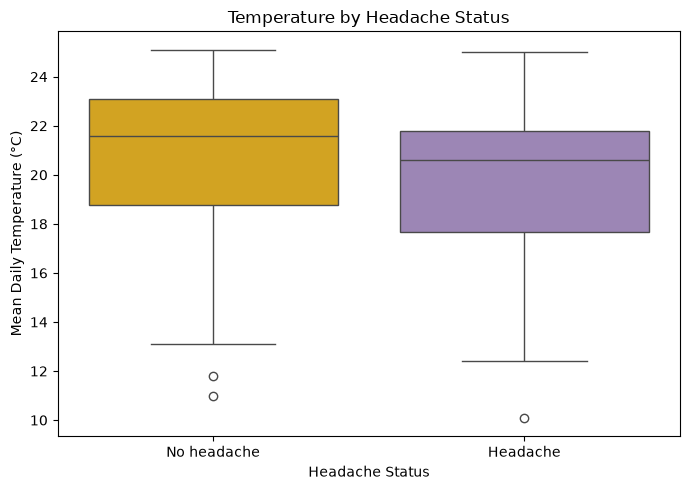

In [18]:
column = 'temperature_2m_mean (°C)'
title = 'Temperature by Headache Status'
ylabel = 'Mean Daily Temperature (°C)'

fig, ax = plt.subplots(figsize=(7, 5))

sns.boxplot(
    data=analysis_df,
    x='headache',
    y=column,
    hue='headache',
    order=[0, 1],
    hue_order=[0, 1],
    palette={0: '#EFB105', 1: '#9B7EBD'},
    dodge=False,
    legend=False,
    showfliers=True,
    ax=ax
)

ax.set_xticks([0, 1], labels=['No headache', 'Headache'])
ax.set_xlabel('Headache Status')
ax.set_ylabel(ylabel)
ax.set_title(title)

plt.tight_layout()
plt.show()

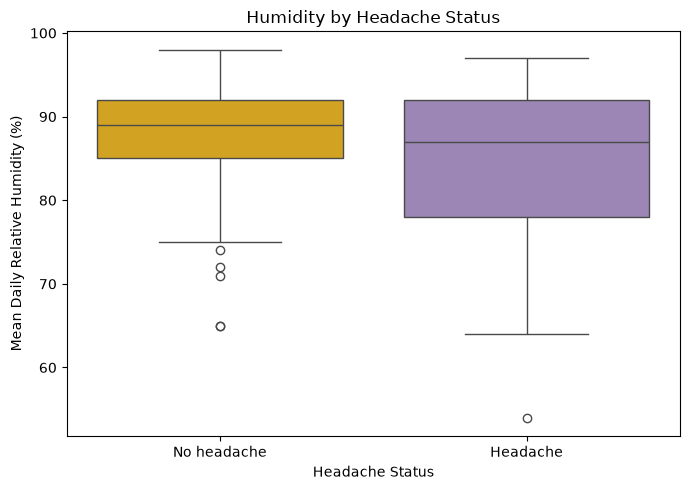

In [20]:
column = 'relative_humidity_2m_mean (%)'
title = 'Humidity by Headache Status'
ylabel = 'Mean Daily Relative Humidity (%)'

fig, ax = plt.subplots(figsize=(7, 5))

sns.boxplot(
    data=analysis_df,
    x='headache',
    y=column,
    hue='headache',
    order=[0, 1],
    hue_order=[0, 1],
    palette={0: '#EFB105', 1: '#9B7EBD'},
    dodge=False,
    legend=False,
    showfliers=True,
    ax=ax
)

ax.set_xticks([0, 1], labels=['No headache', 'Headache'])
ax.set_xlabel('Headache Status')
ax.set_ylabel(ylabel)
ax.set_title(title)

plt.tight_layout()
plt.show()

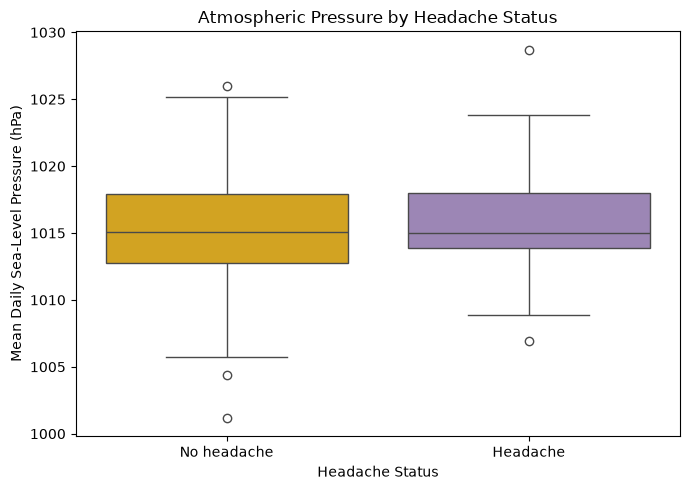

In [21]:
column = 'pressure_msl_mean (hPa)'
title = 'Atmospheric Pressure by Headache Status'
ylabel = 'Mean Daily Sea-Level Pressure (hPa)'

fig, ax = plt.subplots(figsize=(7, 5))

sns.boxplot(
    data=analysis_df,
    x='headache',
    y=column,
    hue='headache',
    order=[0, 1],
    hue_order=[0, 1],
    palette={0: '#EFB105', 1: '#9B7EBD'},
    dodge=False,
    legend=False,
    showfliers=True,
    ax=ax
)

ax.set_xticks([0, 1], labels=['No headache', 'Headache'])
ax.set_xlabel('Headache Status')
ax.set_ylabel(ylabel)
ax.set_title(title)

plt.tight_layout()
plt.show()